In [2]:
!pip install -q langgraph langgraph-checkpoint-sqlite google-genai

In [3]:
import re
import httpx
import os
from dotenv import load_dotenv
from google import genai
from google.genai import types

_ = load_dotenv()

In [4]:
import json
import time
import sqlite3
from typing import TypedDict
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.sqlite import SqliteSaver

In [5]:
api_key = os.environ.get("GEMINI_API_KEY")

if not api_key:
    try:
        from google.colab import userdata
        api_key = userdata.get("GEMINI_API_KEY")
    except Exception:
        pass

if not api_key:
    raise ValueError("No API key found. Set GEMINI_API_KEY as an environment variable or a Colab secret.")

client = genai.Client(api_key=api_key)
MODEL_ID = "gemini-3.6-flash"

print("Client initialized.")

Client initialized.


In [12]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DB_DIR = "/content/drive/MyDrive/dd_agent"
except Exception:
    DB_DIR = "."
os.makedirs(DB_DIR, exist_ok=True)
DB_PATH = os.path.join(DB_DIR, "dd_checkpoints.db")
print("Checkpoint DB:", DB_PATH)

Mounted at /content/drive
Checkpoint DB: /content/drive/MyDrive/dd_agent/dd_checkpoints.db


In [7]:
import os

REPO = "10k-financial-analyst-agent"
if not os.path.exists(REPO):
    !git clone https://github.com/mzs200606/{REPO}.git
else:
    !git -C {REPO} pull
%cd {REPO}

from ratios import FIELDS, REQUIRED, OPTIONAL, with_derived, compute_ratio, compute_all_ratios
from thresholds import THRESHOLDS, SECTORS, classify
from validation import validate_figures
from flags import trend_flags

Cloning into '10k-financial-analyst-agent'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 12 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (12/12), 44.93 KiB | 5.62 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/10k-financial-analyst-agent


In [13]:
def with_retry(fn, tries=3, wait=4):
    """Gemini occasionally returns 429/503. Retry a few times before giving up."""
    for attempt in range(tries):
        try:
            return fn()
        except Exception as e:
            if attempt == tries - 1:
                raise
            print(f"  (Gemini error: {type(e).__name__}. Retrying in {wait}s...)")
            time.sleep(wait)


def upload_pdf_to_gemini(pdf_path):
    """Upload to the Gemini Files API and wait until it is ready. Returns the file object."""
    f = with_retry(lambda: client.files.upload(file=pdf_path))
    while getattr(getattr(f, "state", None), "name", "ACTIVE") == "PROCESSING":
        time.sleep(2)
        f = client.files.get(name=f.name)
    if getattr(getattr(f, "state", None), "name", "ACTIVE") == "FAILED":
        raise RuntimeError("Gemini could not process this PDF.")
    return f


EXTRACTION_PROMPT = """
You are extracting data from a company's 10-K annual report. Use the CONSOLIDATED financial statements (Item 8).
Return ONLY a JSON object, no commentary, with exactly this structure:

{
  "company_name": string,
  "units": "units" | "thousands" | "millions" | "billions",   // the unit the statements are presented in
  "currency": string,
  "fiscal_year_current": string,   // e.g. "FY2025 (ended 2025-12-31)"
  "fiscal_year_prior": string,
  "is_financial_institution": boolean,   // true for banks, insurers, broker-dealers
  "figures": {
    "current": { "<field>": {"value": number or null, "page": integer or null}, ... },
    "prior":   { "<field>": {"value": number or null, "page": integer or null}, ... }
  }
}

"current" = the most recent fiscal year column. "prior" = the immediately preceding fiscal year column.
Each <field> must be one of these, with these exact meanings:
- revenue: total net sales / total revenues
- net_income: net income attributable to the company's shareholders
- ebit: operating income (income from operations). null if not reported.
- interest_expense: interest expense as a POSITIVE number. null if not separately disclosed.
- total_assets
- total_liabilities_and_equity: the balance sheet total of liabilities and equity
- equity: total shareholders' equity attributable to the company (exclude noncontrolling interests)
- current_assets
- current_liabilities
- inventory: null if the company reports no inventory
- receivables: accounts receivable, net (trade receivables)
- short_term_debt: short-term borrowings PLUS current portion of long-term debt. Exclude operating lease liabilities. null if none.
- long_term_debt: non-current debt. Exclude operating lease liabilities. null if none.
- operating_cash_flow: net cash provided by (used in) operating activities

Rules:
- Numbers exactly as printed, in the statements' own units, no commas or currency symbols. Negatives as negative numbers.
- Do NOT add, subtract, or compute anything. Copy single line items only.
- "page" is the page number where you found the figure (approximate is fine).
- If a line item does not exist, use {"value": null, "page": null}. Never guess.
""".strip()


def to_number(x):
    if x is None:
        return None
    if isinstance(x, (int, float)):
        return float(x)
    s = str(x).strip().replace(",", "").replace("$", "")
    neg = s.startswith("(") and s.endswith(")")
    s = s.strip("()")
    try:
        v = float(s)
    except ValueError:
        return None
    return -v if neg else v


def gemini_extract(file_uri, mime_type):
    """Ask Gemini for structured figures. Returns the parsed JSON dict."""
    part = types.Part.from_uri(file_uri=file_uri, mime_type=mime_type)
    response = with_retry(lambda: client.models.generate_content(
        model=MODEL_ID,
        contents=[part, EXTRACTION_PROMPT],
        config=types.GenerateContentConfig(response_mime_type="application/json", temperature=0),
    ))
    raw = (response.text or "").strip()
    raw = re.sub(r"^```(?:json)?|```$", "", raw, flags=re.MULTILINE).strip()
    try:
        return json.loads(raw)
    except json.JSONDecodeError:
        print("Could not parse Gemini output as JSON. Raw output:\n", raw[:2000])
        raise


MEMO_PROMPT = """
You are a financial analyst writing a short due-diligence memo for a human reader.
Use ONLY the numbers in the JSON below. Do not compute new numbers and do not use outside knowledge about the company.
Do NOT give a buy/sell/hold recommendation.

Write (max ~400 words) with these headings:
1. Snapshot (company, period, sector rules applied)
2. What looks healthy (GREEN items)
3. What looks off (RED items and red flags, with the numbers)
4. Questions to ask management (3-5, tied to the flags)
5. Limitations (mention that thresholds are generic rules of thumb for the sector, figures were extracted from the PDF and reviewed by a human, and list any validation WARNINGS)

DATA:
""".strip()


def gemini_stream_memo(payload):
    """Streams the memo to the screen token by token and returns the full text."""
    prompt = MEMO_PROMPT + "\n" + json.dumps(payload, indent=2)
    parts = []
    stream = with_retry(lambda: client.models.generate_content_stream(
        model=MODEL_ID, contents=prompt,
        config=types.GenerateContentConfig(temperature=0.2),
    ))
    for chunk in stream:
        if chunk.text:
            print(chunk.text, end="", flush=True)
            parts.append(chunk.text)
    print()
    return "".join(parts)

In [14]:
class DDState(TypedDict):
    pdf_path: str
    sector: str
    file_name: str
    file_uri: str
    mime_type: str
    company: str
    units: str
    currency: str
    fy_current: str
    fy_prior: str
    is_financial_institution: bool
    figures: dict
    pages: dict
    issues: list
    ratios: dict
    verdicts: dict
    flags: list
    memo: str


def upload_10k(state: DDState):
    print(f"Uploading {state['pdf_path']} to Gemini...")
    f = upload_pdf_to_gemini(state["pdf_path"])
    return {"file_name": f.name, "file_uri": f.uri, "mime_type": f.mime_type}


def extract_figures(state: DDState):
    print("Extracting figures with Gemini (can take 30-90s for a long 10-K)...")
    data = gemini_extract(state["file_uri"], state["mime_type"])
    figures, pages = {"current": {}, "prior": {}}, {"current": {}, "prior": {}}
    for period in ("current", "prior"):
        raw = (data.get("figures") or {}).get(period) or {}
        for k in FIELDS:
            cell = raw.get(k) or {}
            figures[period][k] = to_number(cell.get("value"))
            pages[period][k] = cell.get("page")
        if figures[period]["interest_expense"] is not None:
            figures[period]["interest_expense"] = abs(figures[period]["interest_expense"])
    return {
        "company": data.get("company_name", "Unknown"),
        "units": data.get("units", "unknown"),
        "currency": data.get("currency", ""),
        "fy_current": data.get("fiscal_year_current", ""),
        "fy_prior": data.get("fiscal_year_prior", ""),
        "is_financial_institution": bool(data.get("is_financial_institution", False)),
        "figures": figures,
        "pages": pages,
    }


def validate(state: DDState):
    return {"issues": validate_figures(state["figures"], state)}


def route_after_validate(state: DDState):
    return "blocked" if any(i.startswith("BLOCKER") for i in state["issues"]) else "compute_ratios"


def compute_ratios(state: DDState):
    return {"ratios": {
        "current": compute_all_ratios(state["figures"]["current"]),
        "prior":   compute_all_ratios(state["figures"]["prior"]),
    }}


def assess(state: DDState):
    rules = THRESHOLDS[state["sector"]]
    verdicts = {}
    for name, r in state["ratios"]["current"].items():
        verdicts[name] = {
            "value": r["value"],
            "prior_value": state["ratios"]["prior"][name]["value"],
            "verdict": classify(r["value"], rules[name]),
            "rule": f"{rules[name][0]} is better; green {rules[name][1]}, red {rules[name][2]}",
            "note": r["note"],
        }
    flags = trend_flags(state["figures"]["current"], state["figures"]["prior"])
    if verdicts["ocf_to_net_income"]["verdict"] == "RED":
        flags.append(f"Earnings quality: operating cash flow is only {verdicts['ocf_to_net_income']['value']}x net income.")
    eq = state["figures"]["current"].get("equity")
    if eq is not None and eq <= 0:
        flags.append("Shareholders' equity is zero or negative.")
    return {"verdicts": verdicts, "flags": flags}


def write_memo(state: DDState):
    print("\n--- MEMO (streaming) ---\n")
    payload = {
        "company": state["company"], "period": state["fy_current"], "prior_period": state["fy_prior"],
        "units": state["units"], "currency": state["currency"], "sector_rules": state["sector"],
        "ratios": state["verdicts"], "red_flags": state["flags"],
        "validation_issues": state["issues"],
    }
    return {"memo": gemini_stream_memo(payload)}


builder = StateGraph(DDState)
builder.add_node("upload_10k", upload_10k)
builder.add_node("extract_figures", extract_figures)
builder.add_node("validate", validate)
builder.add_node("compute_ratios", compute_ratios)
builder.add_node("assess", assess)
builder.add_node("write_memo", write_memo)

builder.set_entry_point("upload_10k")
builder.add_edge("upload_10k", "extract_figures")
builder.add_edge("extract_figures", "validate")
builder.add_conditional_edges("validate", route_after_validate,
                              {"compute_ratios": "compute_ratios", "blocked": END})
builder.add_edge("compute_ratios", "assess")
builder.add_edge("assess", "write_memo")
builder.add_edge("write_memo", END)

conn = sqlite3.connect(DB_PATH, check_same_thread=False)
memory = SqliteSaver(conn)
graph = builder.compile(checkpointer=memory, interrupt_before=["compute_ratios"])
print("Graph compiled.")

Graph compiled.


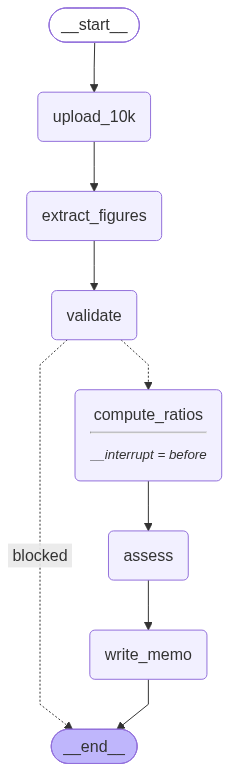

In [15]:
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Could not render the diagram image (needs internet access to mermaid.ink):", e)
    print(graph.get_graph().draw_mermaid())

In [16]:
ICON = {"GREEN": "🟢", "RED": "🔴", "NEUTRAL": "⚪", "N/A": "➖"}


def run(inputs, config):
    """Stream the graph and print a line when each node finishes."""
    for event in graph.stream(inputs, config):
        for node in event:
            if not node.startswith("__"):
                print(f"\n✔ finished node: {node}")


def fmt(v):
    return "—" if v is None else f"{v:,.2f}".rstrip("0").rstrip(".")


def show_review(thread):
    s = graph.get_state(thread).values
    print(f"\n=== REVIEW: {s['company']} | {s['fy_current']} vs {s['fy_prior']} | units: {s['units']} {s['currency']} | sector rules: {s['sector']} ===")
    print(f"{'figure':<30}{'current':>16}{'pg':>8}{'prior':>16}{'pg':>8}")
    for k in FIELDS:
        print(f"{k:<30}{fmt(s['figures']['current'][k]):>16}{str(s['pages']['current'][k] or '—'):>8}"
              f"{fmt(s['figures']['prior'][k]):>16}{str(s['pages']['prior'][k] or '—'):>8}")
    d = with_derived(s["figures"]["current"])["total_debt"]
    dp = with_derived(s["figures"]["prior"])["total_debt"]
    print(f"{'total_debt (derived)':<30}{fmt(d):>16}{'':>8}{fmt(dp):>16}")
    print("\nValidation:", "none, all checks passed" if not s["issues"] else "")
    for i in s["issues"]:
        print("  -", i)


def fix_figure(thread, period, key, value):
    """Correct one figure, re-run validation, and write it back as if the 'validate' node produced it (Lesson 5: update_state + as_node)."""
    assert period in ("current", "prior") and key in FIELDS, f"period must be current/prior; key must be one of {FIELDS}"
    s = graph.get_state(thread).values
    figures = json.loads(json.dumps(s["figures"]))
    pages = json.loads(json.dumps(s["pages"]))
    figures[period][key] = None if value is None else float(value)
    pages[period][key] = "edited"
    issues = validate_figures(figures, s)
    graph.update_state(thread, {"figures": figures, "pages": pages, "issues": issues}, as_node="validate")


def review_and_resume(thread):
    """Interactive loop like the course's 'proceed?' loop: y = approve and continue, e = edit a figure, q = quit."""
    while True:
        snap = graph.get_state(thread)
        show_review(thread)
        blockers = [i for i in snap.values["issues"] if i.startswith("BLOCKER")]
        if blockers:
            choice = input("\nBlocked. [e] edit a figure, [q] quit: ").strip().lower()
        elif snap.next == ("compute_ratios",):
            choice = input("\nApprove these figures? [y] yes and continue, [e] edit a figure, [q] quit: ").strip().lower()
        else:
            print("Nothing to review: the graph is not paused at the review step.")
            return
        if choice == "y" and not blockers:
            run(None, thread)
            return
        if choice == "e":
            period = input("  period (current/prior): ").strip().lower()
            key = input(f"  figure name ({', '.join(FIELDS)}): ").strip()
            raw = input("  new value (number, or 'null'): ").strip().replace(",", "")
            try:
                fix_figure(thread, period, key, None if raw.lower() == "null" else float(raw))
            except (AssertionError, ValueError) as e:
                print("  Could not apply that edit:", e)
        elif choice == "q":
            print("Stopped. The thread is saved; you can come back to it later.")
            return


def show_results(thread, show_memo=False):
    s = graph.get_state(thread).values
    if "verdicts" not in s:
        print("No results yet for this thread.")
        return
    print(f"\n=== RESULTS: {s['company']} | {s['fy_current']} | sector rules: {s['sector']} ===")
    print(f"{'ratio':<20}{'current':>10}{'prior':>10}   verdict   rule")
    for name, v in s["verdicts"].items():
        extra = f"  ({v['note']})" if v["note"] else ""
        print(f"{name:<20}{fmt(v['value']):>10}{fmt(v['prior_value']):>10}   {ICON[v['verdict']]} {v['verdict']:<8} {v['rule']}{extra}")
    print("\nRed flags:", "none" if not s["flags"] else "")
    for f in s["flags"]:
        print("  🚩", f)
    if show_memo:
        print("\n" + s["memo"])

In [17]:
try:
    from google.colab import files
    uploaded = files.upload()
    pdf_path = list(uploaded.keys())[0]
except Exception:
    pdf_path = "your_10k.pdf"
print("Using:", pdf_path)

Saving Walmart_Inc_-_Form_10-K(Mar-14-2025).pdf to Walmart_Inc_-_Form_10-K(Mar-14-2025).pdf
Using: Walmart_Inc_-_Form_10-K(Mar-14-2025).pdf


In [22]:
SECTOR = "general"                      # general | retail | tech | utilities_energy
THREAD_ID = "WMT-FY2025-b"         # change for every new filing
assert SECTOR in SECTORS, f"SECTOR must be one of {SECTORS}"

thread = {"configurable": {"thread_id": THREAD_ID}}
run({"pdf_path": pdf_path, "sector": SECTOR}, thread)
print("\nPaused at:", graph.get_state(thread).next)

Uploading Walmart_Inc_-_Form_10-K(Mar-14-2025).pdf to Gemini...

✔ finished node: upload_10k
Extracting figures with Gemini (can take 30-90s for a long 10-K)...
  (Gemini error: ServerError. Retrying in 4s...)
  (Gemini error: ServerError. Retrying in 4s...)


ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [20]:
review_and_resume(thread)

KeyError: 'company'

In [ ]:
show_results(thread, show_memo=False)


=== RESULTS: Walmart Inc. | FY2025 (ended 2025-01-31) | sector rules: general ===
ratio                  current     prior   verdict   rule
current_ratio             0.82      0.83   🔴 RED      higher is better; green 1.5, red 1.0
quick_ratio               0.24      0.24   🔴 RED      higher is better; green 1.0, red 0.7
debt_to_equity            0.37      0.43   🟢 GREEN    lower is better; green 1.0, red 2.0
interest_coverage            —         —   ➖ N/A      higher is better; green 5.0, red 2.0  (missing input)
net_margin                2.85      2.39   ⚪ NEUTRAL  higher is better; green 10.0, red 2.0
roe                      21.36      18.5   🟢 GREEN    higher is better; green 15.0, red 5.0
roa                       7.45      6.15   🟢 GREEN    higher is better; green 5.0, red 1.0
ocf_to_net_income         1.88       2.3   🟢 GREEN    higher is better; green 1.0, red 0.7

Red flags: 
  🚩 Receivables grew 13.4% vs revenue 5.1% (possible aggressive revenue recognition or collection pr

## 6. OPTIONAL: time travel
Every run saved a checkpoint right before `compute_ratios`. These cells branch from that checkpoint, so you do **not** re-upload or re-extract.
The example re-scores the *same figures* under a different sector's thresholds.

In [ ]:
def review_points(thread):
    """Checkpoints where the graph was paused before compute_ratios, newest first."""
    pts = [s for s in graph.get_state_history(thread) if s.next == ("compute_ratios",)]
    for i, s in enumerate(pts):
        print(f"[{i}] step {s.metadata.get('step')} | sector={s.values.get('sector')} | issues={len(s.values.get('issues', []))}")
    return pts


def branch_from_review(thread, updates, which=0):
    """Fork from a review checkpoint with changed state (e.g. {'sector': 'retail'}), then run the rest of the graph."""
    pts = [s for s in graph.get_state_history(thread) if s.next == ("compute_ratios",)]
    base = pts[which]
    fork_config = graph.update_state(base.config, updates, as_node="validate")
    run(None, fork_config)
    return graph.get_state(thread).config


pts = review_points(thread)

[0] step 3 | sector=general | issues=0


## 7. OPTIONAL: persistence

In [ ]:
thread = {"configurable": {"thread_id": THREAD_ID}}
snap = graph.get_state(thread)
print("Company:", snap.values.get("company"), "| next step:", snap.next)
show_results(thread, show_memo=True)

Company: Walmart Inc. | next step: ()

=== RESULTS: Walmart Inc. | FY2025 (ended 2025-01-31) | sector rules: general ===
ratio                  current     prior   verdict   rule
current_ratio             0.82      0.83   🔴 RED      higher is better; green 1.5, red 1.0
quick_ratio               0.24      0.24   🔴 RED      higher is better; green 1.0, red 0.7
debt_to_equity            0.37      0.43   🟢 GREEN    lower is better; green 1.0, red 2.0
interest_coverage            —         —   ➖ N/A      higher is better; green 5.0, red 2.0  (missing input)
net_margin                2.85      2.39   ⚪ NEUTRAL  higher is better; green 10.0, red 2.0
roe                      21.36      18.5   🟢 GREEN    higher is better; green 15.0, red 5.0
roa                       7.45      6.15   🟢 GREEN    higher is better; green 5.0, red 1.0
ocf_to_net_income         1.88       2.3   🟢 GREEN    higher is better; green 1.0, red 0.7

Red flags: 
  🚩 Receivables grew 13.4% vs revenue 5.1% (possible aggressiv